Number of nodes: 34
Number of edges: 78


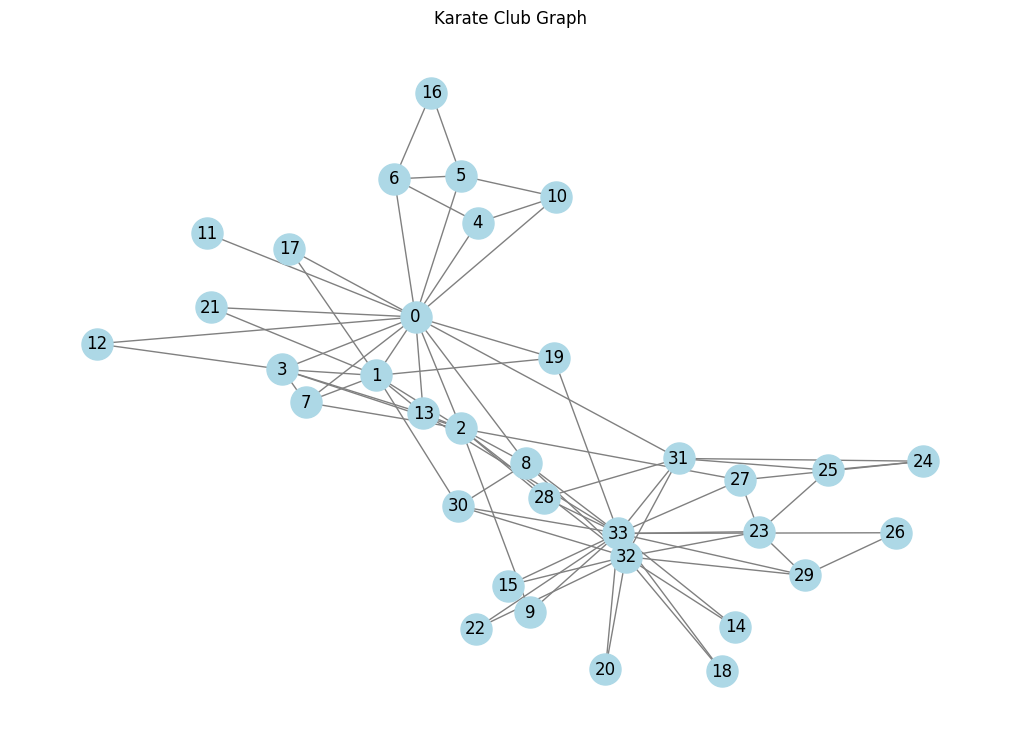

Adjacency Matrix:
[[0. 1. 1. ... 1. 0. 0.]
 [1. 0. 1. ... 0. 0. 0.]
 [1. 1. 0. ... 0. 1. 0.]
 ...
 [1. 0. 0. ... 0. 1. 1.]
 [0. 0. 1. ... 1. 0. 1.]
 [0. 0. 0. ... 1. 1. 0.]]
Degree vector:
[16.  9. 10.  6.  3.  4.  4.  4.  5.  2.  3.  1.  2.  5.  2.  2.  2.  2.
  2.  3.  2.  2.  2.  5.  3.  3.  2.  4.  3.  4.  4.  6. 12. 17.]
Modularity Matrix:
[[-1.64102564  0.07692308 -0.02564103 ...  0.38461538 -1.23076923
  -1.74358974]
 [ 0.07692308 -0.51923077  0.42307692 ... -0.34615385 -0.69230769
  -0.98076923]
 [-0.02564103  0.42307692 -0.64102564 ... -0.38461538  0.23076923
  -1.08974359]
 ...
 [ 0.38461538 -0.34615385 -0.38461538 ... -0.23076923  0.53846154
   0.34615385]
 [-1.23076923 -0.69230769  0.23076923 ...  0.53846154 -0.92307692
  -0.30769231]
 [-1.74358974 -0.98076923 -1.08974359 ...  0.34615385 -0.30769231
  -1.8525641 ]]
Largest Eigenvalue: 4.977080225729887
Leading Eigenvector:
[ 0.38754293  0.26955742  0.13189899  0.25345236  0.13400323  0.14573804
  0.14573804  0.20935954 -0.0

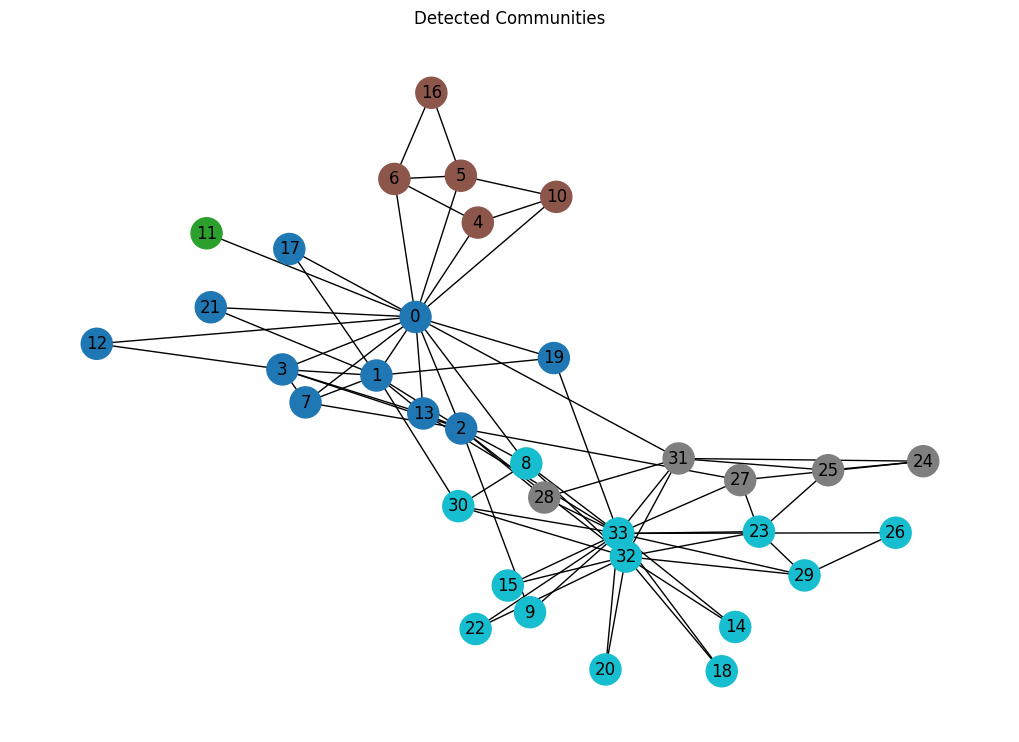

Degree Centrality:
{0: 0.48484848484848486, 1: 0.2727272727272727, 2: 0.30303030303030304, 3: 0.18181818181818182, 4: 0.09090909090909091, 5: 0.12121212121212122, 6: 0.12121212121212122, 7: 0.12121212121212122, 8: 0.15151515151515152, 9: 0.06060606060606061, 10: 0.09090909090909091, 11: 0.030303030303030304, 12: 0.06060606060606061, 13: 0.15151515151515152, 14: 0.06060606060606061, 15: 0.06060606060606061, 16: 0.06060606060606061, 17: 0.06060606060606061, 18: 0.06060606060606061, 19: 0.09090909090909091, 20: 0.06060606060606061, 21: 0.06060606060606061, 22: 0.06060606060606061, 23: 0.15151515151515152, 24: 0.09090909090909091, 25: 0.09090909090909091, 26: 0.06060606060606061, 27: 0.12121212121212122, 28: 0.09090909090909091, 29: 0.12121212121212122, 30: 0.12121212121212122, 31: 0.18181818181818182, 32: 0.36363636363636365, 33: 0.5151515151515151}
Betweenness Centrality:
{0: 0.43763528138528146, 1: 0.053936688311688304, 2: 0.14365680615680618, 3: 0.011909271284271283, 4: 0.0006313131313

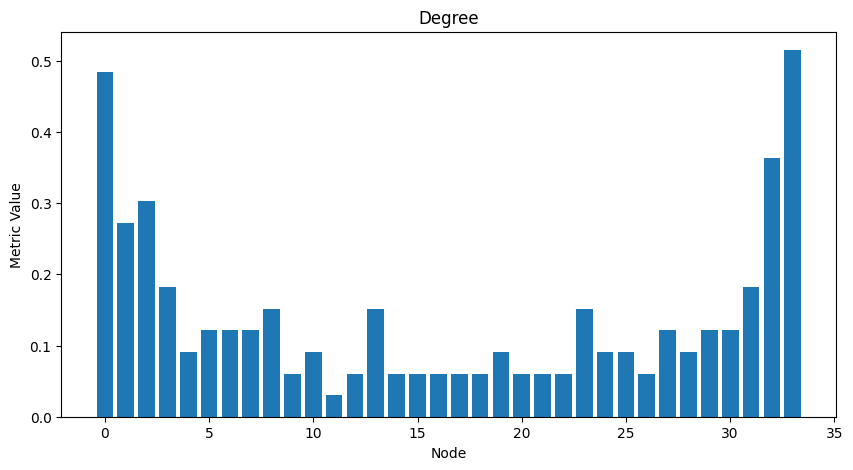

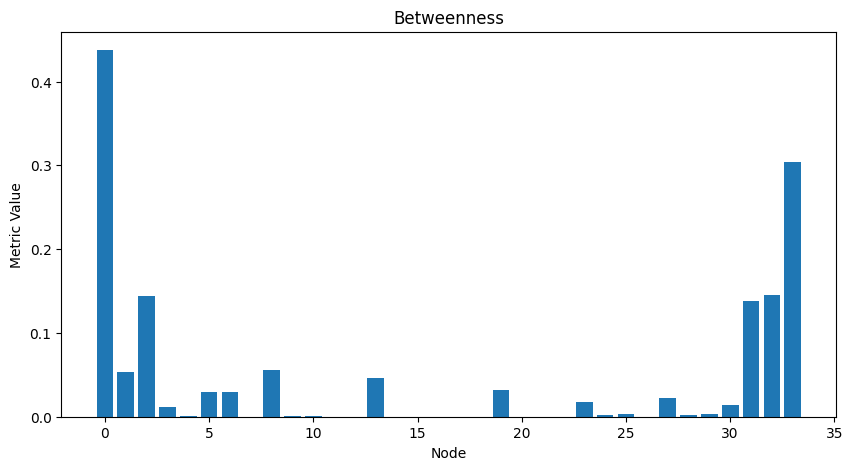

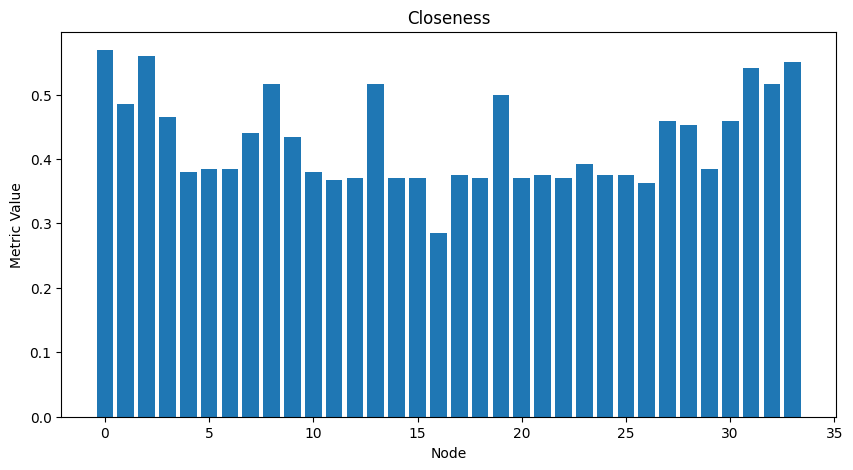

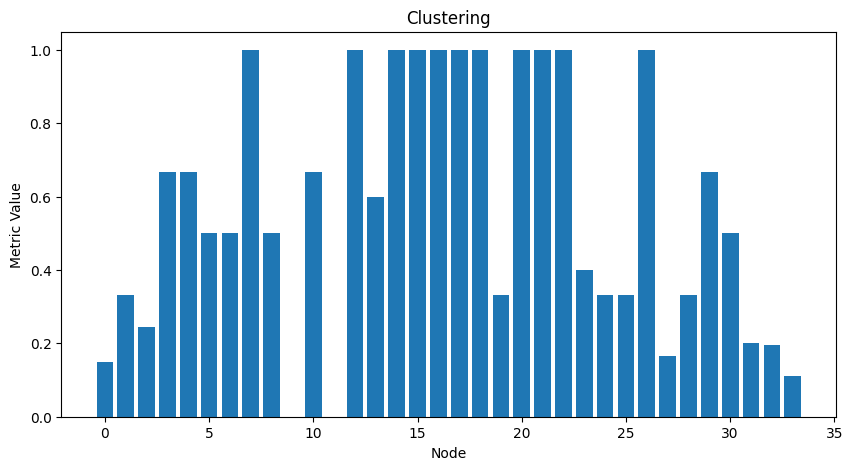

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

G = nx.karate_club_graph()

n = G.number_of_nodes()
m = G.number_of_edges()

print("Number of nodes:", n)
print("Number of edges:", m)
plt.figure(figsize=(10, 7))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G, pos,
    with_labels=True,
    node_color='lightblue',
    node_size=500,
    edge_color='gray'
)

plt.title("Karate Club Graph")
plt.show()
nodes = list(G.nodes())

A = nx.to_numpy_array(
    G, nodelist=nodes, weight=None
)

print("Adjacency Matrix:")
print(A)
k = A.sum(axis=1)

B = A - np.outer(k, k) / (2*m)

print("Degree vector:")
print(k)

print("Modularity Matrix:")
print(B)
eigenvalues, eigenvectors = np.linalg.eigh(B)

largest_eigenvalue = eigenvalues[-1]

largest_eigenvector = eigenvectors[:, -1]

print("Largest Eigenvalue:", largest_eigenvalue)
print("Leading Eigenvector:")
print(largest_eigenvector)
eigenvalues, eigenvectors = np.linalg.eigh(B)

largest_eigenvalue = eigenvalues[-1]

largest_eigenvector = eigenvectors[:, -1]

print("Largest Eigenvalue:", largest_eigenvalue)
print("Leading Eigenvector:")
print(largest_eigenvector)
s = np.where(largest_eigenvector > 0, 1, -1)

gain = (s.T @ B @ s) / (4*m)

print("Modularity Gain:", gain)
def recursive_partition(B, nodes, m):

    communities = []
    split_log = []

    def divide(C):

        indices = [nodes.index(i) for i in C]

        BC = B[np.ix_(indices, indices)]

        values, vectors = np.linalg.eigh(BC)

        largest = values[-1]
        vector = vectors[:, -1]

        if largest <= 1e-10:
            communities.append(C)
            return
        group1 = [
            v for v, x in zip(C, vector) if x > 0
        ]

        group2 = [
            v for v, x in zip(C, vector) if x <= 0
        ]

        if len(group1) == 0 or len(group2) == 0:
            communities.append(C)
            return

        s = np.where(vector > 0, 1, -1)

        gain = (s.T @ BC @ s) / (4*m)

        if gain <= 1e-10:
            communities.append(C)
            return
        split_log.append({
            "group1": group1,
            "group2": group2,
            "eigenvalue": largest,
            "gain": gain
        })

        divide(group1)
        divide(group2)

    divide(list(nodes))

    return communities, split_log


communities, split_log = recursive_partition(B, nodes, m)

print("Final Communities:")

for i, c in enumerate(communities):
    print("Community", i+1, ":", c)
node_colors = {}

for i, community in enumerate(communities):
    for node in community:
        node_colors[node] = i

colors = [
    node_colors[node] for node in G.nodes()
]

plt.figure(figsize=(10, 7))

nx.draw(
    G,
    pos,
    with_labels=True,
    node_color=colors,
    cmap=plt.cm.tab10,
    node_size=500
)
plt.title("Detected Communities")
plt.show()
degree = nx.degree_centrality(G)

print("Degree Centrality:")
print(degree)
betweenness = nx.betweenness_centrality(G)

print("Betweenness Centrality:")
print(betweenness)
closeness = nx.closeness_centrality(G)

print("Closeness Centrality:")
print(closeness)
clustering = nx.clustering(G)

print("Clustering Coefficient:")
print(clustering)
df = pd.DataFrame({
    "Degree": degree,
    "Betweenness": betweenness,
    "Closeness": closeness,
    "Clustering": clustering
})

print(df)
metrics = {
    "Degree": degree,
    "Betweenness": betweenness,
    "Closeness": closeness,
    "Clustering": clustering
}

for name, values in metrics.items():

    plt.figure(figsize=(10, 5))

    plt.bar(values.keys(), values.values())

    plt.title(name)
    plt.xlabel("Node")
    plt.ylabel("Metric Value")

    plt.show()